In [1]:
%load_ext autoreload
%autoreload 2


In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from bgflow.utils import (assert_numpy, distance_vectors, distances_from_vectors, 
                          remove_mean, IndexBatchIterator, LossReporter, as_numpy, compute_distances
)
from bgflow import (GaussianMCMCSampler, DiffEqFlow, BoltzmannGenerator, Energy, Sampler, 
                    MultiDoubleWellPotential, MeanFreeNormalDistribution, KernelDynamics, 
                    BlackBoxDynamics, TimeIndependentDynamics, DenseNet)
from bgflow.bg import sampling_efficiency
import ot as pot
import tqdm
from eq_ot_flow.models import EGNN_dynamics
from eq_ot_flow.utilities import superpose_points, superpose_points_batch
from eq_ot_flow.estimator import BruteForceEstimatorFast
from scipy.optimize import linear_sum_assignment


In [5]:
# first define system dimensionality and a target energy/distribution

dim = 8
n_particles = 4
n_dimensions = dim // n_particles

# DW parameters
a=0.9
b=-4
c=0
offset=4

target = MultiDoubleWellPotential(dim, n_particles, a, b, c, offset, two_event_dims=False)

In [6]:
# define a MCMC sampler to sample from the target energy

dw4_data = np.load("data/dw4-dataidx.npy", allow_pickle=True)
all_data = remove_mean(dw4_data[0], n_particles, n_dimensions)
idx = dw4_data[1]
data = all_data[idx[:100000]]
val_data = all_data[idx[100000:500000]]
data_holdout = all_data[idx[-500000:]]
data_holdout.shape

torch.Size([500000, 8])

In [8]:
n_data = 100000
data_smaller = data[:n_data].clone()
data_smaller = data_smaller
data_smaller.shape



In [10]:
# now set up a prior
prior =  MeanFreeNormalDistribution(dim, n_particles, two_event_dims=False).cuda()
prior_cpu = MeanFreeNormalDistribution(dim, n_particles, two_event_dims=False)

In [18]:
# Build the Boltzmann Generator

net_dynamics = EGNN_dynamics(n_particles=n_particles, device='cuda',  n_dimension=dim // n_particles, hidden_nf=32,
    act_fn=torch.nn.SiLU(), n_layers=3, recurrent=True, tanh=True, attention=True, condition_time=True, mode='egnn_dynamics', agg='sum')


bb_dynamics = BlackBoxDynamics(
    dynamics_function=net_dynamics,
    divergence_estimator=BruteForceEstimatorFast()
)
flow = DiffEqFlow(
    dynamics=bb_dynamics
)
# having a flow and a prior, we can now define a Boltzmann Generator

bg = BoltzmannGenerator(prior, flow, target).cuda()

In [19]:
# train with convex mixture of NLL and KL loss

n_batch = 256
batch_iter = IndexBatchIterator(len(data_smaller), n_batch)

optim = torch.optim.Adam(bg.parameters(), lr=5e-4)

n_epochs = 50
n_report_steps = 5

reporter = LossReporter("NLL")


In [20]:
# start with 5e-4 for 200 epochs
# 5e-5 for 200


In [1]:
## Note, in practice the batch reordering should not be done during training

In [ ]:
sigma = 0.01
for epoch in range(n_epochs):
    for it, idxs in enumerate(batch_iter):

        optim.zero_grad()
        x1 = data[idxs]#.cuda()
        batchsize = x1.shape[0]
        t = torch.rand(batchsize, 1).cuda()
        x0 = prior_cpu.sample(batchsize)
        # Resample x0, x1 according to transport matrix
        a1, b1 = pot.unif(x0.size()[0]), pot.unif(x1.size()[0])
        #M = torch.cdist(x0, x1) ** 2
        M = torch.zeros(batchsize, batchsize)
        for i in range(batchsize):
            points2_reordered = []
            points1 = x0[i].reshape(n_particles, n_dimensions)#.cpu()

            for j in range(batchsize):
                # define two sets of points
                points2 = x1[j].reshape(n_particles, n_dimensions)#.cpu()

                # compute pairwise distances between the two sets of points
                distances = torch.cdist(points1, points2)

                # use the Hungarian algorithm to solve the assignment problem
                row_idx, col_idx = linear_sum_assignment(distances**2)

                # reorder the second set of points according to the optimal assignment
                points2_reordered.append(points2[col_idx].unsqueeze(0))
            # Find optimal rotation
            superposed_points2 = superpose_points_batch(torch.cat(points2_reordered, dim=0), reference=points1)
            M[i] = torch.cdist(points1.reshape(1, -1), superposed_points2.reshape(batchsize, -1))[0]

        M = M**2
        M = M / M.max()
        pi = pot.emd(a1, b1, M.detach().cpu().numpy())
        # Sample random interpolations on pi
        p = pi.flatten()
        p = p / p.sum()
        choices = np.random.choice(pi.shape[0] * pi.shape[1], p=p, size=batchsize)
        i, j = np.divmod(choices, pi.shape[1])
        x0 = x0[i]
        x1 = x1[j]
        for i in range(batchsize):
            # define two sets of points
            points1 = x0[i].reshape(n_particles, n_dimensions)#.cpu()
            points2 = x1[i].reshape(n_particles, n_dimensions)#.cpu()

            # compute pairwise distances between the two sets of points
            distances = torch.cdist(points1, points2)

            # use the Hungarian algorithm to solve the assignment problem
            row_idx, col_idx = linear_sum_assignment(distances**2)

            # reorder the second set of points according to the optimal assignment and rotate
            x1[i] = superpose_points(x1[i].reshape(n_particles, n_dimensions)[col_idx],
                                     x0[i].reshape(n_particles, n_dimensions)).flatten()
        x0 = x0.cuda()
        x1 = x1.cuda()
        mu_t = t * x1 + (1 - t) * x0
        sigma_t = sigma
        noise = prior.sample(batchsize)
        x = mu_t + sigma_t * noise
        ut = x1 - x0
        vt = bg.flow._dynamics._dynamics._dynamics_function(t, x)
        loss = torch.mean((vt - ut) ** 2)
        loss.backward()
        optim.step()
        reporter.report(loss)
        if it % n_report_steps == 0:
            print("\repoch: {0}, iter: {1}/{2}, loss: {3:.4}".format(
                    epoch,
                    it,
                    len(batch_iter),
                    *reporter.recent(1).ravel()
                ), end="")


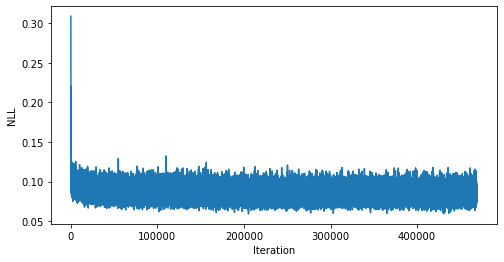

In [80]:
reporter.plot()

In [ ]:
# load a model
# eq OT flow matching
# PATH = "models/DW4_eq_OT_flow_matching"
# OT flow matching
# PATH = "models/DW4_OT_flow_matching"
# bg.load_state_dict(torch.load(PATH))

In [68]:
bg.flow._integrator_atol = 1e-5
bg.flow._integrator_rtol = 1e-5
flow._use_checkpoints = False
flow._kwargs = {}


n_samples = 1000
n_sample_batches = 50
latent_np = np.empty(shape=(0))
samples_np = np.empty(shape=(0))
log_w_np = np.empty(shape=(0))
energies_np = np.empty(shape=(0))
distances_x_np = np.empty(shape=(0))

for i in tqdm.tqdm(range(n_sample_batches)):
    with torch.no_grad(): 
        samples, latent, dlogp = bg.sample(n_samples, with_latent=True, with_dlogp=True)
        #latent = latent[0]
        log_weights = bg.log_weights_given_latent(samples, latent, dlogp, normalize=False).detach().cpu().numpy()
        latent_np = np.append(latent_np, latent.detach().cpu().numpy())
        samples_np = np.append(samples_np, samples.detach().cpu().numpy())
        distances_x = distances_from_vectors(distance_vectors(samples.view(-1, n_particles, n_dimensions))).detach().cpu().numpy().reshape(-1)
        distances_x_np = np.append(distances_x_np, distances_x)

        log_w_np = np.append(log_w_np, log_weights)
        energies = target.energy(samples).detach().cpu().numpy()
        energies_np = np.append(energies_np, energies)
        

latent_np = latent_np.reshape(-1, dim)
samples_np = samples_np.reshape(-1, dim)

100%|███████████████████████████████████████████| 50/50 [04:24<00:00,  5.29s/it]


In [69]:
sampling_efficiency(torch.from_numpy(log_w_np)).item()

0.9013580443281618

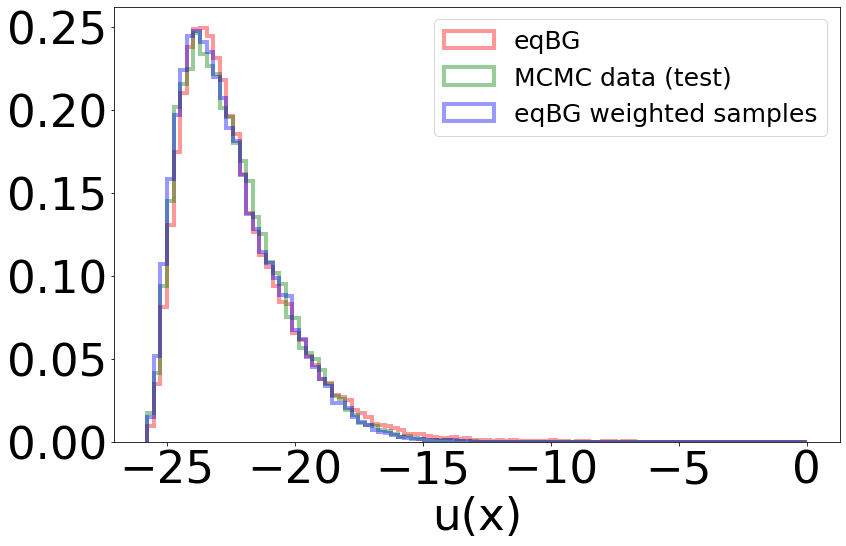

In [72]:
energies_data = target.energy(data).detach().cpu().numpy()
energies_bg = energies_np

energies_prior = target.energy(latent).detach().cpu().numpy()

min_energy = min(energies_data.min(), energies_bg.min(), energies_prior.min())
max_energy = max(energies_data.max(), energies_bg.max(), energies_prior.max())

plt.figure(figsize=(16,9))
plt.hist(energies_bg, bins=100, density=True,  range=(min_energy, 0), alpha=0.4, histtype='step', linewidth=4,
         color="r", label="eqBG");

plt.hist(energies_data, bins=100, density=True, range=(min_energy, 0), alpha=0.4, color="g", histtype='step', linewidth=4, 
         label="MCMC data (test)");
plt.hist(energies_bg.reshape(-1), bins=100, density=True,  range=(min_energy, 0), alpha=0.4, histtype='step', linewidth=4,
         color="b", label="eqBG weighted samples", weights=np.exp(log_w_np));


plt.xlabel("u(x)", fontsize=45)  
plt.xticks(fontsize=45) 
plt.yticks(fontsize=45);
plt.legend( fontsize=25);

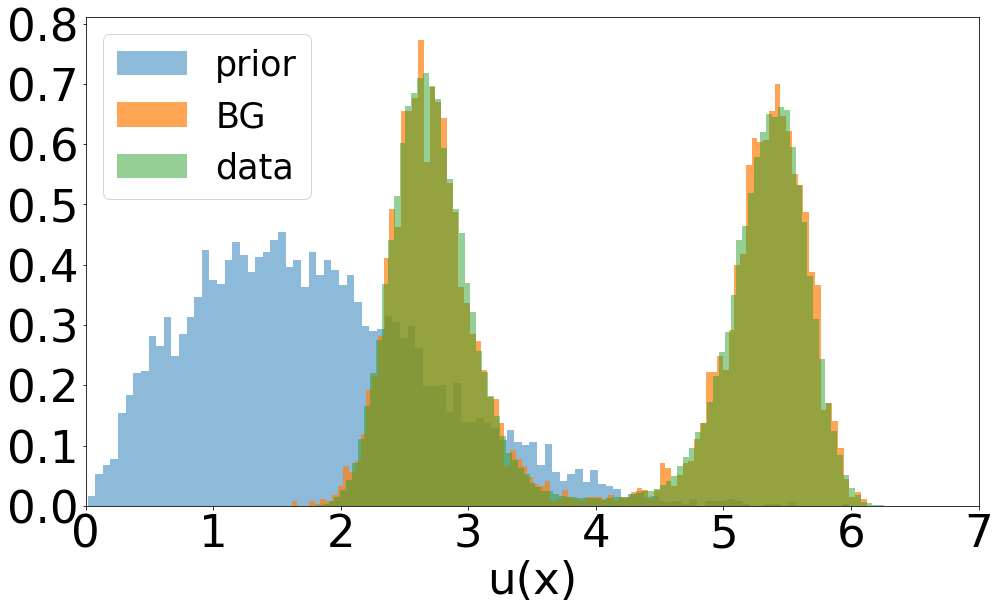

In [73]:
dists = distances_from_vectors(
            distance_vectors(data.view(-1, n_particles, dim // n_particles)))
dists_prior = distances_from_vectors(
            distance_vectors(latent.view(-1, n_particles, dim // n_particles)))


plt.figure(figsize=(16,9))
plt.hist(as_numpy(dists_prior.view(-1)[::2]), bins=100, density=True, alpha=0.5, label="prior");
plt.hist(as_numpy(distances_x[::2]), bins=100, label="BG", alpha=0.7, density=True,  linewidth=4);
plt.hist(as_numpy(dists.view(-1)[::2]), bins=100, label="data", alpha=0.5, density=True,  linewidth=4);
plt.xlim(0,7)
plt.legend(fontsize=35)
plt.xlabel("u(x)", fontsize=45)  
plt.xticks(fontsize=45) 
plt.yticks(fontsize=45);

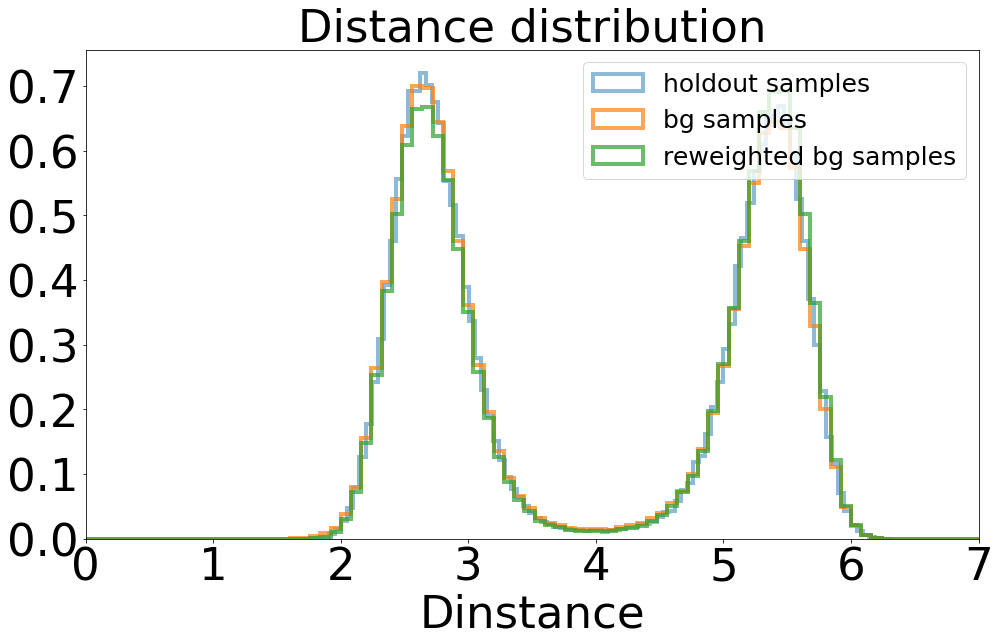

In [75]:
dists = distances_from_vectors(
            distance_vectors(data_holdout.view(-1, n_particles, dim // n_particles)))

plt.figure(figsize=(16,9))
plt.hist(as_numpy(dists.view(-1)), bins=100, label="holdout samples", alpha=0.5, density=True, histtype='step', linewidth=4);
plt.hist(distances_x_np, bins=100, label="bg samples", alpha=0.7, density=True, histtype='step', linewidth=4, range=(0,8));
plt.hist(distances_x_np, bins=100, label="reweighted bg samples", alpha=0.7, density=True, histtype='step',
         linewidth=4, weights=np.repeat(np.exp(log_w_np).flatten(), n_particles*(n_particles-1)), range=(0,8));
plt.xlim(0,7)
plt.legend(fontsize=25)
plt.xlabel("Dinstance", fontsize=45)  
plt.xticks(fontsize=45) 
plt.yticks(fontsize=45);
plt.title("Distance distribution", fontsize=45);


In [22]:
import tqdm
data_holdout = data_holdout
batch_size=1000
n = len(data_holdout) // batch_size
nll = 0

for i in tqdm.tqdm(range(n)):
    batch = data_holdout[i*batch_size:i*batch_size+ batch_size].cuda()
    with torch.no_grad():
        nll += bg.energy(batch).mean() / n

nll

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [29:48<00:00,  3.58s/it]


tensor(1.6707, device='cuda:0')

In [23]:
nll

tensor(1.6707, device='cuda:0')

In [24]:
import tqdm
batch_size=1000
n = len(data_smaller) // batch_size
nll_data_smaller = 0

for i in tqdm.tqdm(range(n)):
    batch = data_smaller[i*batch_size:i*batch_size+ batch_size].cuda()
    with torch.no_grad():
        nll_data_smaller += bg.energy(batch).mean() / n

nll_data_smaller

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [05:56<00:00,  3.57s/it]


tensor(1.6770, device='cuda:0')

In [25]:
nll_data_smaller

tensor(1.6770, device='cuda:0')